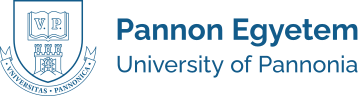

# Kísérlettervezés: 2³ faktoros kísérlet, hatások szignifikanciája, kölcsönhatás és robusztus beállítás

A notebook

1. a $2^3$ teljes faktoros kísérlet adataiból becsli a főhatásokat és a kölcsönhatásokat, a kísérleti hibát az ismétlésekből, és t-próbával jelöli a szignifikáns hatásokat (Montgomery, 2017);
2. Pareto-ábrán mutatja a hatásokat a szignifikancia határával;
3. kölcsönhatási ábrát rajzol a tervezési és a zajtényező között;
4. a tervezési tényezők minden beállítására kiszámítja a válasz átlagát és a zajtényező hatását, és kiválasztja a robusztus beállítást.

A beépített példa a KoboCella csavarozási nyomatéka (kézikönyv 18. fejezet).

[Megnyitás Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/rendszermernokseg/blob/main/gyakorlat/notebookok/doe.ipynb) · Rendszermérnöki eszköztár – Gyakorlati útmutató · Abonyi János · CC BY-NC-SA 4.0 (szöveg), MIT (kód)

**Használat.** Futtasd a cellákat sorban (Colabban: *Futtatókörnyezet → Összes futtatása*). A notebook alapértelmezésben a beépített példaadatokkal dolgozik.
Saját adataidhoz töltsd ki a [`doe_sablon.xlsx`](https://complexsystemsintelligence.github.io/rendszermernokseg/gyakorlat/sablonok/doe_sablon.xlsx) sablont, állítsd a `SAJAT_SABLON` változót `True` értékre, és futtatáskor töltsd fel a fájlt.

A módszer leírása és értelmezése: Gyakorlati útmutató, Kísérlettervezés eszközlap.

In [ ]:
SAJAT_SABLON = False   # True: a kitöltött doe_sablon.xlsx

import sys, os
COLABBAN = "google.colab" in sys.modules

def sablon_betoltese(alapnev):
    """Visszaadja a feltöltött vagy a notebook mellett lévő sablon útvonalát."""
    if COLABBAN:
        from google.colab import files
        print("Válaszd ki a kitöltött sablont:")
        feltoltott = files.upload()
        return next(iter(feltoltott))
    for jelolt in (alapnev, os.path.join("..", "sablonok", alapnev)):
        if os.path.exists(jelolt):
            return jelolt
    raise FileNotFoundError(f"Nem találom: {alapnev}")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Adatok

In [ ]:
if SAJAT_SABLON:
    fajl = sablon_betoltese("doe_sablon.xlsx")
    t = pd.read_excel(fajl, sheet_name="Tényezők", header=None)
    nevek = dict(zip(["A", "B", "C"], t.iloc[3:6, 1].astype(str)))
    szintek = {k: (str(t.iloc[3 + i, 2]), str(t.iloc[3 + i, 3])) for i, k in enumerate("ABC")}
    tipus = dict(zip(["A", "B", "C"], t.iloc[3:6, 4].astype(str)))
    cel = float(t.iloc[8, 3]) if pd.notna(t.iloc[8, 3]) else None
    k = pd.read_excel(fajl, sheet_name="Kísérlet", header=2).iloc[:8]
    sorok = []
    for _, r in k.iterrows():
        for y in r.iloc[7:10]:
            if pd.notna(y):
                sorok.append({"A": int(r.iloc[1]), "B": int(r.iloc[2]), "C": int(r.iloc[3]), "y": float(y)})
    d = pd.DataFrame(sorok)
else:
    nevek = {"A": "végső fordulatszám", "B": "csavarozási stratégia", "C": "bitbetét állapota"}
    szintek = {"A": ("alacsony", "magas"), "B": ("egylépcsős", "kétlépcsős"), "C": ("új", "kopott")}
    tipus = {"A": "tervezési", "B": "tervezési", "C": "zaj"}
    cel = 4.0
    Y = {(-1, -1, -1): [4.036, 4.077], (-1, -1, 1): [3.872, 3.952], (-1, 1, -1): [3.978, 3.947], (-1, 1, 1): [3.913, 3.956],
         (1, -1, -1): [4.145, 4.115], (1, -1, 1): [3.973, 3.949], (1, 1, -1): [4.058, 4.087], (1, 1, 1): [4.046, 4.045]}
    d = pd.DataFrame([{"A": a, "B": b, "C": c, "y": y} for (a, b, c), ys in Y.items() for y in ys])
print(f"{len(d)} mérés; tervezési tényezők: {[k for k, v in tipus.items() if v == 'tervezési']}; zajtényezők: {[k for k, v in tipus.items() if v == 'zaj']}")

## Hatások és szignifikancia

In [ ]:
X = d[["A", "B", "C"]].astype(float).copy()
for a, b in (("A", "B"), ("A", "C"), ("B", "C")):
    X[a + b] = X[a] * X[b]
X["ABC"] = X.A * X.B * X.C
atl = d.groupby(["A", "B", "C"]).y.mean()
hatas = {c: d.y[X[c] == 1].mean() - d.y[X[c] == -1].mean() for c in X.columns}
N, p = len(d), 8
M = np.column_stack([np.ones(N), X.to_numpy()])
beta, *_ = np.linalg.lstsq(M, d.y.to_numpy(), rcond=None)
res = d.y.to_numpy() - M @ beta
df = N - p
s = np.sqrt((res ** 2).sum() / df) if df > 0 else np.nan
se = 2 * s / np.sqrt(N)
tkrit = stats.t.ppf(0.975, df) if df > 0 else np.nan
tab = pd.DataFrame({"hatás": hatas, "t": {k: v / se for k, v in hatas.items()}})
tab["p"] = 2 * stats.t.sf(np.abs(tab.t), df) if df > 0 else np.nan
tab["szignifikáns"] = tab.p < 0.05
print(f"kísérleti hiba szórása s = {s:.4f} (df = {df}); a hatások standard hibája {se:.4f}; t kritikus = {tkrit:.2f}")
tab.round(4)

## Robusztus beállítás

In [ ]:
terv = [k for k, v in tipus.items() if v == "tervezési"]
zaj = [k for k, v in tipus.items() if v == "zaj"]
sor = []
for beall in itertools.product([-1, 1], repeat=len(terv)):
    m = d.copy()
    for k, v in zip(terv, beall):
        m = m[m[k] == v]
    zaj_atl = m.groupby(zaj).y.mean()
    sor.append({**{nevek[k]: szintek[k][(v + 1) // 2] for k, v in zip(terv, beall)},
                "átlag": m.y.mean(), "zajhatás": zaj_atl.max() - zaj_atl.min(),
                "eltérés a céltól": (m.y.mean() - cel) if cel is not None else np.nan})
rob = pd.DataFrame(sor).sort_values("zajhatás")
print("A legrobusztusabb beállítás (a zajtényező hatása a legkisebb):")
print(rob.iloc[0].to_string())
rob.round(4)

## Ábra

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axs[0]
srt = tab.reindex(tab.hatás.abs().sort_values().index)
ax.barh(srt.index, srt.hatás.abs(), color=["#285780" if s_ else "#B8CEE4" for s_ in srt.szignifikáns])
ax.axvline(tkrit * se, color="#B83A3A", ls="--"); ax.text(tkrit * se, -0.6, " 5%-os határ", color="#B83A3A", fontsize=8)
ax.set_xlabel("|hatás|"); ax.set_title("A hatások Pareto-ábrája", fontsize=10)
ax = axs[1]
bz = terv[-1] if len(terv) else "B"
z = zaj[0] if zaj else "C"
for sz, c, mk in ((-1, "#E07B39", "o"), (1, "#285780", "s")):
    v = d[d[bz] == sz].groupby(z).y.mean()
    ax.plot([0, 1], v.to_numpy(), marker=mk, color=c, lw=2, label=f"{nevek[bz]}: {szintek[bz][(sz + 1) // 2]}")
if cel is not None:
    ax.axhline(cel, color="#999999", ls=":")
ax.set_xticks([0, 1]); ax.set_xticklabels([f"{nevek[z]}: {szintek[z][0]}", szintek[z][1]], fontsize=8)
ax.legend(fontsize=8); ax.set_ylabel("átlagos válasz"); ax.set_title(f"Kölcsönhatás: {bz} × {z}", fontsize=10)
ax = axs[2]
ax.scatter(rob["zajhatás"].abs(), rob["átlag"], s=60, color="#285780")
for _, r in rob.iterrows():
    ax.annotate(" / ".join(str(r[nevek[k]]) for k in terv), (abs(r["zajhatás"]), r["átlag"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
if cel is not None:
    ax.axhline(cel, color="#999999", ls=":")
ax.set_xlabel("a zajtényező hatása (|max − min|)"); ax.set_ylabel("átlagos válasz")
ax.set_title("Tervezési beállítások: átlag és robusztusság", fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("doe.png", bbox_inches="tight", dpi=150); plt.show()

## Értelmezés

- Három hatás szignifikáns: a fordulatszám (A) és a bitbetét állapota (C) főhatása, valamint a csavarozási stratégia és a bitbetét kölcsönhatása (B×C). A stratégia főhatása elhanyagolható: önmagában nem változtatja az átlagot.
- A B×C kölcsönhatás a robusztusság kulcsa: kétlépcsős stratégiánál a kopott bitbetét alig csökkenti a nyomatékot, egylépcsősnél jelentősen. A zajtényező hatását tehát a tervezési tényező megfelelő beállításával lehet semlegesíteni.
- A két kétlépcsős beállítás a legrobusztusabb (a zajhatás mindkettőnél kb. 0,03 Nm). Átlaguk a célérték két oldalán van (kb. 3,95 és 4,06 Nm), ezért a középértéket a fordulatszám köztes beállításával lehet a célértékre hangolni: a szórásérzékenységet a stratégia, a középértéket a fordulatszám állítja be.